# Lab-07 — Introduction to PyTorch and CNN-Based Image Classification  
## Part I: PyTorch Fundamentals — Feedforward Neural Network and MNIST CNN

**Course:** Deep Learning  
**Session:** 2026–27  
**Department:** Electronics Engineering, Ramdeobaba University, Nagpur

### Part-I learning progression
1. PyTorch tensors and device selection  
2. `Dataset` and `DataLoader`  
3. Feedforward neural network using `nn.Module`  
4. Forward pass → loss → backpropagation → parameter update  
5. Evaluation using `model.eval()` and `torch.no_grad()`  
6. CNN for MNIST handwritten-digit classification  
7. Layer-by-layer dimension tracing  
8. Learning curves, prediction visualization, and error analysis

> **Important:** In theoretical CNN calculations, use the standard order \(H\times W\times C\).  
> PyTorch image tensors use the implementation order **[N, C, H, W]**.


## Course Outcome Mapping

This part primarily supports:

- **CO1:** Apply best practices for dataset preparation, preprocessing, and hyperparameter tuning to develop and evaluate deep learning models for real-world datasets.
- **CO2:** Design and implement fully connected deep neural network architectures using vectorized computation techniques.
- **CO3:** Design and implement convolutional neural network architectures and analyze the effect of architectural parameters on model performance.
- **CO6:** Analyze and optimize key architectural and training parameters to enhance the performance and generalization of deep learning models.


## 1. Setup
Run the next cell first. It imports PyTorch, plotting tools, and the supporting files supplied with this lab.


In [1]:
import os, sys, math, random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch version:", torch.__version__)
print("Using device:", device)


PyTorch version: 2.11.0+cpu
Using device: cpu


### Supporting files
Upload these files to the same Colab runtime before running the next cell:

- `testCases_lab07_part1.py`
- `public_tests_lab07_part1.py`
- `lab07_part1_utils.py`

The public tests validate selected student-written functions without giving away their implementation.


In [3]:
from public_tests_lab07_part1 import (
    test_feedforward_model, test_mnist_cnn, test_batch_accuracy, run_all_tests
)
from lab07_part1_utils import (
    count_trainable_parameters, plot_history, show_mnist_batch, denormalize_mnist
)
print("Supporting files imported.")


Supporting files imported.


## 2. PyTorch tensors and device selection

A PyTorch tensor stores numerical data together with:
- a **shape**,
- a **data type (`dtype`)**, and
- a **device** (CPU/GPU).

Complete the short exercise below.


In [4]:
# Guided example
a = torch.tensor([[1., 2., 3.],
                  [4., 5., 6.]])
b = torch.ones_like(a)

print("a =\n", a)
print("shape :", a.shape)
print("dtype :", a.dtype)
print("device:", a.device)
print("a + b =\n", a + b)

# Matrix multiplication example
M1 = torch.randn(2, 3)
M2 = torch.randn(3, 4)
print("Matrix-product shape:", (M1 @ M2).shape)


a =
 tensor([[1., 2., 3.],
        [4., 5., 6.]])
shape : torch.Size([2, 3])
dtype : torch.float32
device: cpu
a + b =
 tensor([[2., 3., 4.],
        [5., 6., 7.]])
Matrix-product shape: torch.Size([2, 4])


In [ ]:
# STUDENT TASK 1
# Create a 2x3 tensor named x, print shape/dtype/device,
# move it to `device`, and perform:
# (a) element-wise addition with a compatible tensor
# (b) matrix multiplication with a compatible matrix.

# YOUR CODE STARTS HERE


# YOUR CODE ENDS HERE


## 3. Example 1 — Feedforward Neural Network

We use a small synthetic **3-class classification** dataset so that the PyTorch training mechanism remains transparent.

Architecture:

$
n_x \rightarrow 16 \rightarrow 8 \rightarrow N_{\mathrm{class}}
$

For a linear layer,
$
Z^{[l]} = W^{[l]}A^{[l-1]} + b^{[l]}.
$
The final layer must return **logits**. Do **not** add Softmax when using `nn.CrossEntropyLoss()`.


### 3.1 Generate and split the dataset


In [5]:
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X, y = make_blobs(
    n_samples=1200,
    centers=3,
    n_features=4,
    cluster_std=2.2,
    random_state=SEED
)

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Classes:", np.unique(y_train))


Training: (960, 4) (960,)
Validation: (240, 4) (240,)
Classes: [0 1 2]


### 3.2 Convert NumPy arrays to tensors and mini-batches


In [6]:
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.long)
X_val_t = torch.tensor(X_val, dtype=torch.float32)
y_val_t = torch.tensor(y_val, dtype=torch.long)

train_dataset = TensorDataset(X_train_t, y_train_t)
val_dataset = TensorDataset(X_val_t, y_val_t)

BATCH_SIZE = 32
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

xb, yb = next(iter(train_loader))
print("Mini-batch X:", xb.shape)
print("Mini-batch y:", yb.shape)


Mini-batch X: torch.Size([32, 4])
Mini-batch y: torch.Size([32])


### 3.3 Define `FeedForwardNN` — student-completion cell

Complete only the missing layers. The public test checks:
- inheritance from `nn.Module`,
- output shape,
- total number of trainable parameters.


In [11]:
class FeedForwardNN(nn.Module):
    def __init__(self, n_x, n_classes):
        super().__init__()

        # Architecture required: n_x -> 16 -> 8 -> n_classes
        # Complete the missing layers.
        self.network = nn.Sequential(
            nn.Linear(n_x, 16),
            nn.ReLU(),

            # YOUR CODE STARTS HERE
            nn.Linear(16, 8),
            nn.ReLU(),
            nn.Linear(8, n_classes)

            # YOUR CODE ENDS HERE
        )

    def forward(self, x):
        return self.network(x)

n_x = X_train.shape[1]
n_classes = len(np.unique(y_train))
ffn = FeedForwardNN(n_x, n_classes).to(device)
print(ffn)


FeedForwardNN(
  (network): Sequential(
    (0): Linear(in_features=4, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=3, bias=True)
  )
)


In [12]:
test_feedforward_model(FeedForwardNN)


✓ FeedForwardNN: passed


### 3.4 Parameter-count exercise

For a dense layer with $n_{\mathrm{in}}$ inputs and $n_{\mathrm{out}}$ outputs:

$
N_{\mathrm{params}} = n_{\mathrm{in}}n_{\mathrm{out}} + n_{\mathrm{out}}.
$

Calculate the parameter count manually before running the verification cell.


In [13]:
manual_params = (
    (n_x * 16 + 16) +
    (16 * 8 + 8) +
    (8 * n_classes + n_classes)
)
actual_params = count_trainable_parameters(ffn)

print("Manual parameter count :", manual_params)
print("PyTorch parameter count:", actual_params)
assert manual_params == actual_params


Manual parameter count : 243
PyTorch parameter count: 243


### 3.5 Accuracy helper — student-completion cell


In [14]:
def batch_accuracy(logits, y_true):
    """
    Return the fraction of correctly classified examples in one mini-batch.
    """
    # YOUR CODE STARTS HERE
    predictions = torch.argmax(logits, dim=1)
    accuracy = (predictions == y_true).float().mean()
    return accuracy.item()
    raise NotImplementedError("Complete batch_accuracy()")
    # YOUR CODE ENDS HERE


In [15]:
test_batch_accuracy(batch_accuracy)


✓ batch_accuracy: passed


### 3.6 One training epoch

Observe the recurring PyTorch sequence:

`zero_grad()` → model forward call → criterion → `backward()` → `step()`.


In [16]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    running_correct = 0
    n = 0

    for X_batch, y_batch in loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()
        logits = model(X_batch)
        loss = criterion(logits, y_batch)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * X_batch.size(0)
        running_correct += (logits.argmax(dim=1) == y_batch).sum().item()
        n += X_batch.size(0)

    return running_loss / n, running_correct / n

@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    running_correct = 0
    n = 0

    for X_batch, y_batch in loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        logits = model(X_batch)
        loss = criterion(logits, y_batch)

        running_loss += loss.item() * X_batch.size(0)
        running_correct += (logits.argmax(dim=1) == y_batch).sum().item()
        n += X_batch.size(0)

    return running_loss / n, running_correct / n


### 3.7 Train the feedforward network and plot learning curves


Epoch 01/25 | train loss 1.0596 | train acc 0.333 | val loss 1.0127 | val acc 0.333
Epoch 05/25 | train loss 0.5121 | train acc 0.911 | val loss 0.4186 | val acc 0.975
Epoch 10/25 | train loss 0.0553 | train acc 1.000 | val loss 0.0498 | val acc 1.000
Epoch 15/25 | train loss 0.0171 | train acc 1.000 | val loss 0.0173 | val acc 1.000
Epoch 20/25 | train loss 0.0086 | train acc 1.000 | val loss 0.0091 | val acc 1.000
Epoch 25/25 | train loss 0.0055 | train acc 1.000 | val loss 0.0057 | val acc 1.000


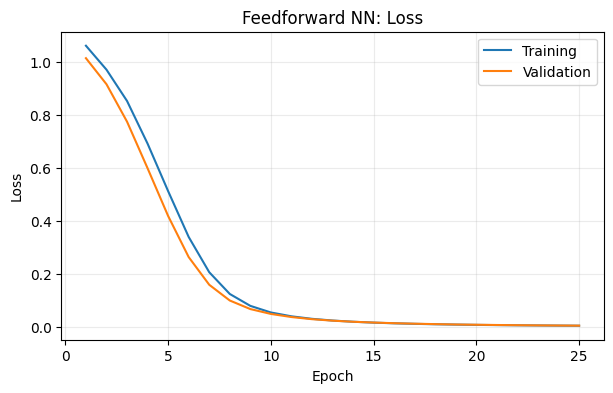

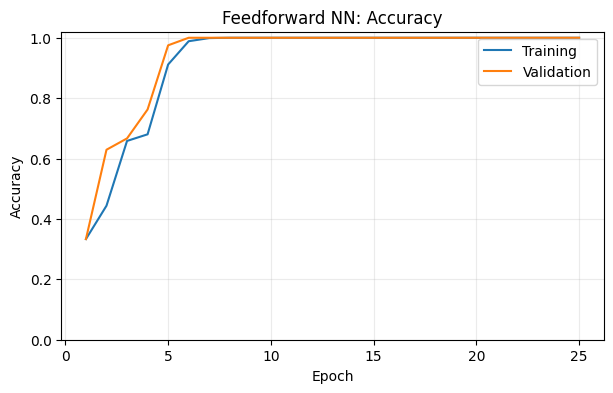

In [17]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(ffn.parameters(), lr=1e-3)

EPOCHS = 25
ffn_history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

for epoch in range(EPOCHS):
    tr_loss, tr_acc = train_one_epoch(ffn, train_loader, criterion, optimizer, device)
    va_loss, va_acc = evaluate(ffn, val_loader, criterion, device)

    ffn_history["train_loss"].append(tr_loss)
    ffn_history["val_loss"].append(va_loss)
    ffn_history["train_acc"].append(tr_acc)
    ffn_history["val_acc"].append(va_acc)

    if epoch == 0 or (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch+1:02d}/{EPOCHS} | "
              f"train loss {tr_loss:.4f} | train acc {tr_acc:.3f} | "
              f"val loss {va_loss:.4f} | val acc {va_acc:.3f}")

plot_history(ffn_history, "Feedforward NN")


### Part-I Example 1 observations
Record:
- \(n_x\)
- number of classes
- batch size
- learning rate
- epochs
- trainable parameters
- final training accuracy
- validation accuracy

Then answer: **Why is `model.eval()` needed even though this particular FNN has no Dropout or BatchNorm?**


# 4. Example 2 — CNN for MNIST Handwritten-Digit Classification

MNIST contains 10 digit classes. The theoretical image dimension is

$
28\times 28\times 1.
$

PyTorch batches are stored as:

$
[N,C,H,W] = [N,1,28,28].
$

We use the standard CNN notation:
- $F$: convolution filter size
- $P$: padding
- $S$: stride
- $K$: number of filters
- $F_{\mathrm{pool}}$: pooling-window size
- $S_{\mathrm{pool}}$: pooling stride


### 4.1 Load and normalize MNIST


100%|██████████| 9.91M/9.91M [00:00<00:00, 12.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 341kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.20MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.68MB/s]


Batch image tensor: torch.Size([128, 1, 28, 28])
Batch label tensor: torch.Size([128])


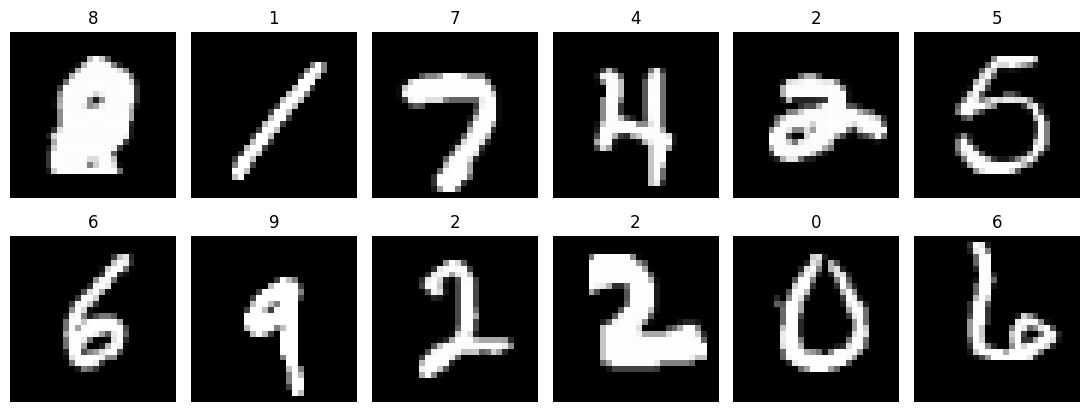

In [18]:
from torchvision import datasets, transforms

mnist_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

mnist_train = datasets.MNIST(
    root="./data", train=True, download=True, transform=mnist_transform
)
mnist_test = datasets.MNIST(
    root="./data", train=False, download=True, transform=mnist_transform
)

MNIST_BATCH = 128
mnist_train_loader = DataLoader(
    mnist_train, batch_size=MNIST_BATCH, shuffle=True, num_workers=2, pin_memory=torch.cuda.is_available()
)
mnist_test_loader = DataLoader(
    mnist_test, batch_size=MNIST_BATCH, shuffle=False, num_workers=2, pin_memory=torch.cuda.is_available()
)

images, labels = next(iter(mnist_train_loader))
print("Batch image tensor:", images.shape)
print("Batch label tensor:", labels.shape)

show_mnist_batch(images, labels, n=12)


### 4.2 Trace the CNN dimensions before coding

For convolution:

$
H_{\mathrm{out}}
=
\left\lfloor
\frac{H_{\mathrm{in}}+2P-F}{S}
\right\rfloor+1.
$

For pooling (normally $P_{\mathrm{pool}}=0$):

$
H_{\mathrm{out}}
=
\left\lfloor
\frac{H_{\mathrm{in}}-F_{\mathrm{pool}}}{S_{\mathrm{pool}}}
\right\rfloor+1.
$

Complete this table in your record **before running the model**:

| Stage | Parameters | Output \(H\times W\times C\) |
|---|---|---|
| Input | — | $28\times28\times1$ |
| Conv1 | $F=3, P=1, S=1, K=16$ | ? |
| MaxPool1 | $F_{\mathrm{pool}}=2,S_{\mathrm{pool}}=2$ | ? |
| Conv2 | $F=3, P=1, S=1, K=32$ | ? |
| MaxPool2 | $F_{\mathrm{pool}}=2,S_{\mathrm{pool}}=2$ | ? |
| Flatten | — | ? |
| Dense | — | 64 |
| Output | — | 10 logits |


### 4.3 Define the MNIST CNN — student-completion cell


In [19]:
class MNISTCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            # YOUR CODE STARTS HERE
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)

            # YOUR CODE ENDS HERE
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            # After two 2x2 pooling layers: 28 -> 14 -> 7
            nn.Linear(32 * 7 * 7, 64),
            nn.ReLU(),
            nn.Linear(64, 10)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

mnist_model = MNISTCNN().to(device)
print(mnist_model)
print("Trainable parameters:", count_trainable_parameters(mnist_model))


MNISTCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=64, bias=True)
    (2): ReLU()
    (3): Linear(in_features=64, out_features=10, bias=True)
  )
)
Trainable parameters: 105866


In [20]:
test_mnist_cnn(MNISTCNN)


✓ MNISTCNN: passed


### 4.4 Verify intermediate tensor shapes


In [21]:
with torch.no_grad():
    x = images[:4].to(device)
    print("Input       :", tuple(x.shape))
    for layer in mnist_model.features:
        x = layer(x)
        print(f"{layer.__class__.__name__:12s}: {tuple(x.shape)}")


Input       : (4, 1, 28, 28)
Conv2d      : (4, 16, 28, 28)
ReLU        : (4, 16, 28, 28)
MaxPool2d   : (4, 16, 14, 14)
Conv2d      : (4, 32, 14, 14)
ReLU        : (4, 32, 14, 14)
MaxPool2d   : (4, 32, 7, 7)


### 4.5 Train the MNIST CNN
For a classroom Colab run, 3–5 epochs are usually sufficient to demonstrate the workflow.


Epoch 01/4 | train loss 0.2340 | train acc 0.929 | test loss 0.0647 | test acc 0.980
Epoch 02/4 | train loss 0.0610 | train acc 0.981 | test loss 0.0453 | test acc 0.984
Epoch 03/4 | train loss 0.0434 | train acc 0.986 | test loss 0.0432 | test acc 0.985
Epoch 04/4 | train loss 0.0351 | train acc 0.989 | test loss 0.0331 | test acc 0.989


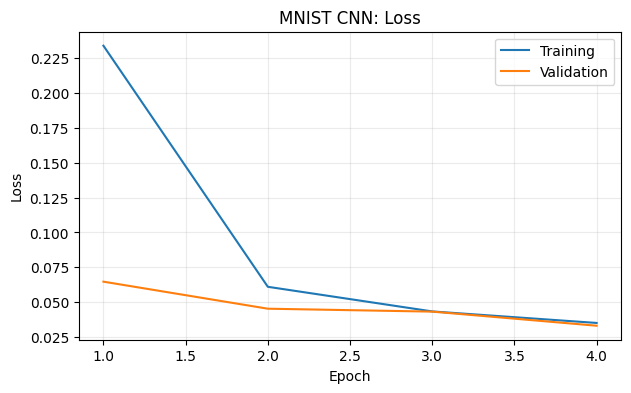

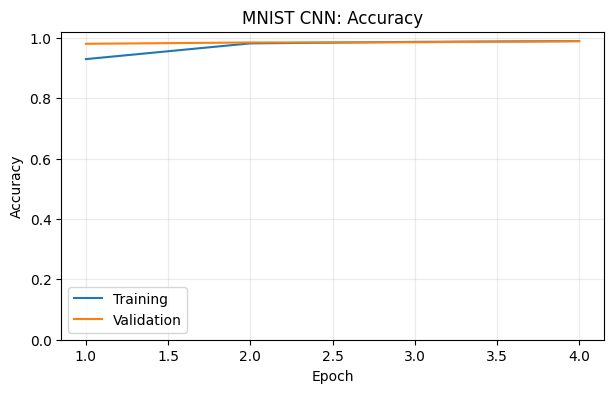

In [22]:
mnist_criterion = nn.CrossEntropyLoss()
mnist_optimizer = torch.optim.Adam(mnist_model.parameters(), lr=1e-3)

MNIST_EPOCHS = 4
mnist_history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

for epoch in range(MNIST_EPOCHS):
    tr_loss, tr_acc = train_one_epoch(
        mnist_model, mnist_train_loader, mnist_criterion, mnist_optimizer, device
    )
    te_loss, te_acc = evaluate(
        mnist_model, mnist_test_loader, mnist_criterion, device
    )

    mnist_history["train_loss"].append(tr_loss)
    mnist_history["val_loss"].append(te_loss)
    mnist_history["train_acc"].append(tr_acc)
    mnist_history["val_acc"].append(te_acc)

    print(f"Epoch {epoch+1:02d}/{MNIST_EPOCHS} | "
          f"train loss {tr_loss:.4f} | train acc {tr_acc:.3f} | "
          f"test loss {te_loss:.4f} | test acc {te_acc:.3f}")

plot_history(mnist_history, "MNIST CNN")


### 4.6 Inspect predictions and misclassified digits


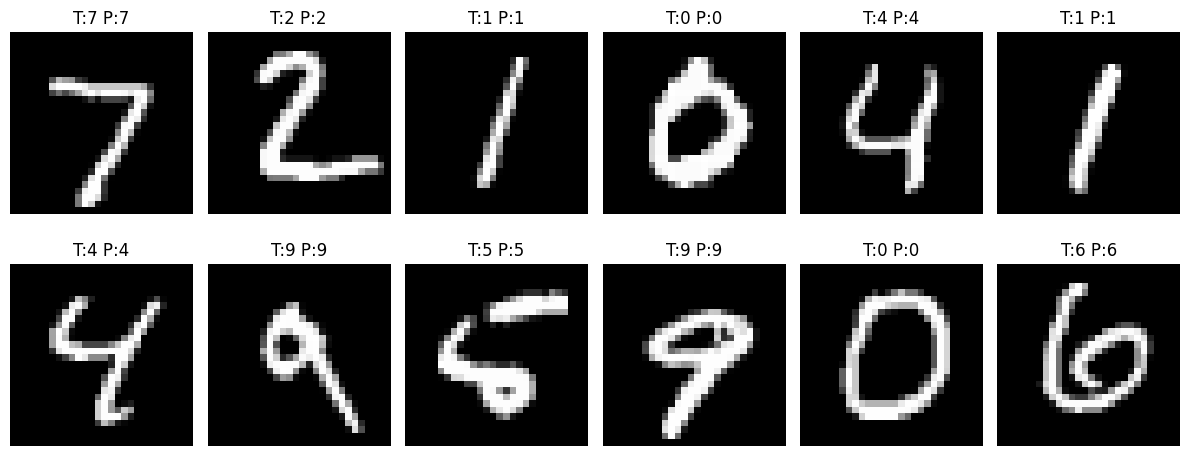

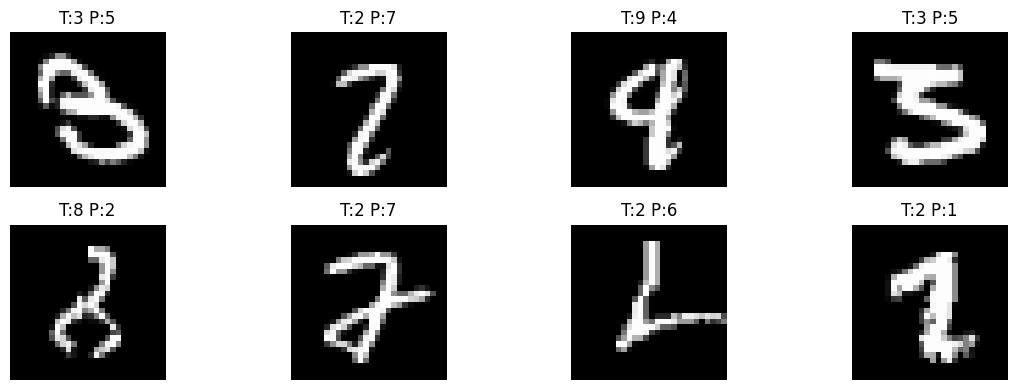

In [23]:
@torch.no_grad()
def collect_predictions(model, loader, device, max_items=None):
    model.eval()
    all_images, all_true, all_pred = [], [], []
    for X_batch, y_batch in loader:
        logits = model(X_batch.to(device))
        pred = logits.argmax(dim=1).cpu()
        all_images.append(X_batch.cpu())
        all_true.append(y_batch.cpu())
        all_pred.append(pred)
        if max_items and sum(len(x) for x in all_true) >= max_items:
            break
    return (
        torch.cat(all_images)[:max_items],
        torch.cat(all_true)[:max_items],
        torch.cat(all_pred)[:max_items]
    )

test_imgs, test_true, test_pred = collect_predictions(
    mnist_model, mnist_test_loader, device, max_items=2000
)

# Show 12 predictions
plt.figure(figsize=(12,5))
for i in range(12):
    plt.subplot(2,6,i+1)
    img = denormalize_mnist(test_imgs[i]).squeeze().numpy()
    plt.imshow(img, cmap="gray")
    plt.title(f"T:{int(test_true[i])} P:{int(test_pred[i])}")
    plt.axis("off")
plt.tight_layout()
plt.show()

# Show up to 8 errors
wrong = torch.where(test_true != test_pred)[0][:8]
if len(wrong) == 0:
    print("No errors in inspected subset.")
else:
    plt.figure(figsize=(12,4))
    for j, idx in enumerate(wrong):
        plt.subplot(2,4,j+1)
        img = denormalize_mnist(test_imgs[idx]).squeeze().numpy()
        plt.imshow(img, cmap="gray")
        plt.title(f"T:{int(test_true[idx])} P:{int(test_pred[idx])}")
        plt.axis("off")
    plt.tight_layout()
    plt.show()


### 4.7 Student analysis
For at least five misclassified digits, comment on one or more of:
- unusual stroke shape,
- ambiguous digit structure,
- rotation/slant,
- faint or broken strokes,
- visual similarity with the predicted class.

Also answer:
1. Why are convolutional layers more suitable than a fully connected layer applied directly to raw images?
2. Why does the number of channels change after convolution but normally remain unchanged after pooling?
3. What would happen to the flatten dimension if the second pooling layer were removed?


## 5. Final Part-I Public Check


## Part-I submission checklist
- All guided cells executed.
- Student-completion cells finished.
- FNN parameter calculations recorded.
- FNN learning curves included.
- MNIST layer dimensions calculated before verification.
- MNIST training/test curves included.
- At least 12 predictions shown.
- At least five errors analyzed.
- Final public tests passed.
